# Observability planner

Given an object name (searched in SIMBAD) or its coordinates, a date and an observatory, this notebook computes:

- sunset, sunrise and twilight times
- the altitude of the target during the night and when it can be observed
- the Moon phase and its position
- a plot of the altitude of the target and the Moon along the night

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation, AltAz, get_body
from astroquery.simbad import Simbad

## Input

`TARGET` is the name of the object. If you want to use coordinates instead, write them in
`RA` and `DEC` (otherwise leave them as `None`).

In [6]:
TARGET = "HD 10700"
RA = "01:44:04.08"        # e.g. "01:44:04.1"
DEC = "-15:56:14.9"       # e.g. "-15:56:15"

DATE = "2026-11-20"   # local date of the evening
SITE = "CASLEO"

MIN_ALT = 30     # minimum altitude to observe (deg)

## Observatories
Latitude, longitude (deg), elevation (m) and time difference with UT (hours).

In [7]:
observatories = {
    "CASLEO": {"lat": -31.7986, "lon": -69.2956, "elev": 2552, "utc_offset": -3},
    "OAFA":   {"lat": -31.8023, "lon": -69.3265, "elev": 2348, "utc_offset": -3},
}

obs = observatories[SITE]
location = EarthLocation(lat=obs["lat"] * u.deg, lon=obs["lon"] * u.deg, height=obs["elev"] * u.m)
utc_offset = obs["utc_offset"] * u.hour

## Target coordinates

In [8]:
if RA is not None and DEC is not None:
    coord = SkyCoord(RA, DEC, unit=(u.hourangle, u.deg))
    vmag = 3.5
else:
    simbad = Simbad()
    simbad.add_votable_fields("V")
    result = simbad.query_object(TARGET)
    coord = SkyCoord(result["ra"][0], result["dec"][0], unit=u.deg)
    vmag = result["V"][0]

print("Target:", TARGET)
print("RA  =", coord.ra.to_string(unit=u.hourangle, sep=":", precision=1))
print("DEC =", coord.dec.to_string(sep=":", precision=1))
if vmag is not None:
    print("V   =", vmag)

Target: HD 10700
RA  = 1:44:04.1
DEC = -15:56:14.9
V   = 3.5


## Times along the night
From noon of the observing date to noon of the next day, every 2 minutes.

In [9]:
noon = Time(DATE + " 12:00:00") - utc_offset          # local noon, in UT
times = noon + np.arange(0, 24 * 60, 2) * u.min
local_hours = np.arange(0, 24 * 60, 2) / 60 + 12      # 12 ... 36 (36 = noon of next day)

frame = AltAz(obstime=times, location=location)
sun_alt = get_body("sun", times, location).transform_to(frame).alt.deg
moon_altaz = get_body("moon", times, location).transform_to(frame)
target_altaz = coord.transform_to(frame)

moon_alt = moon_altaz.alt.deg
target_alt = target_altaz.alt.deg

## Sunset, sunrise and twilights
Since the grid starts at noon, the first time the Sun is below a given altitude is the evening
event and the last one is the morning event.

In [14]:
def to_hhmm(hour):
    hour = hour % 24
    return f"{int(hour):02d}:{int(round((hour % 1) * 60)) % 60:02d}"


events = {"Sun": -0.833} #, "Civil twilight": -6, "Nautical twilight": -12, "Astronomical twilight": -18}

print(f"{'':25s} {'evening':>8s} {'morning':>8s}")
for name, alt in events.items():
    below = local_hours[sun_alt < alt]
    print(f"{name:25s} {to_hhmm(below[0]):>8s} {to_hhmm(below[-1]):>8s}")

                           evening  morning
Sun                          20:20    06:26


## Moon
The illuminated fraction is calculated from the angle between the Sun and the Moon.

In [11]:
midnight = noon + 12 * u.hour
sun = get_body("sun", midnight, location)
moon = get_body("moon", midnight, location)
elongation = sun.separation(moon).deg
illumination = (1 - np.cos(np.radians(elongation))) / 2

# waxing if the Sun-Moon angle grows during the next day
moon_tomorrow = get_body("moon", midnight + 1 * u.day, location)
sun_tomorrow = get_body("sun", midnight + 1 * u.day, location)
waxing = sun_tomorrow.separation(moon_tomorrow).deg > elongation

if illumination < 0.05:
    phase = "New Moon"
elif illumination > 0.95:
    phase = "Full Moon"
elif waxing:
    phase = "Waxing"
else:
    phase = "Waning"

print(f"Moon: {phase}, {illumination * 100:.0f}% illuminated")

# moonrise: the altitude goes from negative to positive (and the opposite for moonset)
rises = local_hours[1:][(moon_alt[:-1] < 0) & (moon_alt[1:] >= 0)]
sets = local_hours[1:][(moon_alt[:-1] >= 0) & (moon_alt[1:] < 0)]
for t in rises:
    print("Moonrise:", to_hhmm(t))
for t in sets:
    print("Moonset: ", to_hhmm(t))

Moon: Waxing, 84% illuminated
Moonrise: 16:20
Moonset:  03:56


## Is the target observable?
The target is observable when it is above `MIN_ALT` and the Sun is below −18° (astronomical night).

In [12]:
dark = sun_alt < -18
observable = dark & (target_alt > MIN_ALT)
hours = observable.sum() * 2 / 60

i_max = np.argmax(target_alt)
print(f"Maximum altitude: {target_alt[i_max]:.1f} deg at {to_hhmm(local_hours[i_max])}")

if hours > 0:
    best = np.argmax(np.where(observable, target_alt, -90))
    moon_sep = target_altaz[best].separation(moon_altaz[best]).deg
    print(f"Observable for {hours:.1f} h, from {to_hhmm(local_hours[observable][0])} "
          f"to {to_hhmm(local_hours[observable][-1])}")
    print(f"Best time: {to_hhmm(local_hours[best])}, altitude {target_alt[best]:.1f} deg, "
          f"airmass {target_altaz[best].secz:.2f}")
    print(f"Distance to the Moon at that time: {moon_sep:.0f} deg")
else:
    print("The target is not observable this night")

Maximum altitude: 74.0 deg at 23:22
Observable for 5.8 h, from 21:54 to 03:38
Best time: 23:22, altitude 74.0 deg, airmass 1.04
Distance to the Moon at that time: 30 deg


## Plot

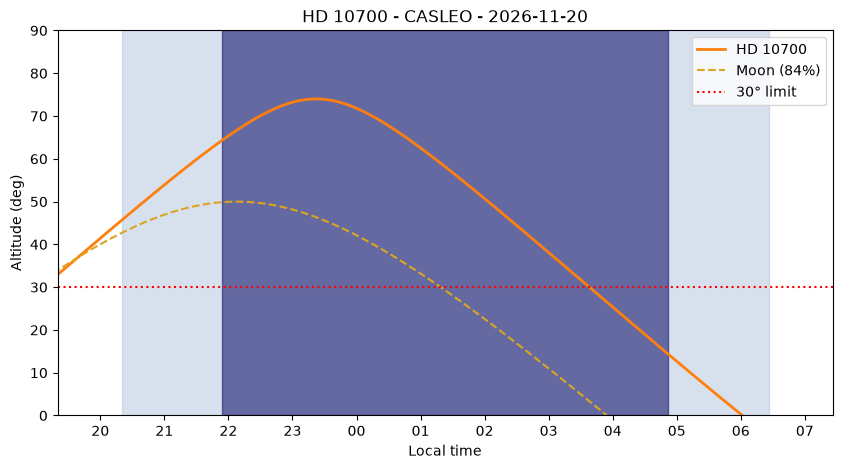

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))

# shade the night: lighter during twilight, darker during astronomical night
ax.fill_between(local_hours, 0, 90, where=sun_alt < -0.833, color="lightsteelblue", alpha=0.5)
ax.fill_between(local_hours, 0, 90, where=sun_alt < -18, color="midnightblue", alpha=0.6)

ax.plot(local_hours, target_alt, color="tab:orange", lw=2, label=TARGET)
ax.plot(local_hours, moon_alt, "--", color="goldenrod", label=f"Moon ({illumination * 100:.0f}%)")
ax.axhline(MIN_ALT, color="red", ls=":", label=f"{MIN_ALT}° limit")

sunset = local_hours[sun_alt < -0.833][0]
sunrise = local_hours[sun_alt < -0.833][-1]
ax.set_xlim(sunset - 1, sunrise + 1)
ax.set_ylim(0, 90)

ticks = np.arange(np.ceil(sunset - 1), sunrise + 1)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{int(t % 24):02d}" for t in ticks])

ax.set_xlabel("Local time")
ax.set_ylabel("Altitude (deg)")
ax.set_title(f"{TARGET} - {SITE} - {DATE}")
ax.legend(loc="upper right")
plt.show()